In [1]:
get_ipython().run_line_magic("load_ext", "autoreload")  # dev-only
get_ipython().run_line_magic("autoreload", "2")  # dev-only

# Лабораторная работа 1. Нейронные сети для табличных данных

## Постановка задачи

Мультиклассовая классификация оценки `quality` (3–8) красного вина по 11 физико-химическим признакам (UCI Wine Quality). Основная метрика — F1 macro (выбор моделей по val); дополнительно balanced accuracy, F1 weighted и ROC AUC OvR.

Протокол: одно разбиение train/val/test = 1023/256/320. Test тот же, что в ml-2 ЛР1 (stratified 20 %, `random_state=42`). Preprocessing учится только на train, test используется только для итоговой оценки.

Модели: CatBoost (baseline), FT-Transformer, GANDALF (часть I), TabLDM, TabM (часть II).

Все результаты в ноутбуке получены полными прогонами. Быстрый режим (аналог `FAST_MODE = True`) использовался только для проверки pipeline.

# I. Нейронные сети для табличных данных по учебным примерам

## 1.1 Набор данных

UCI Wine Quality (красное вино): 1599 объектов, 11 числовых признаков, категориальных нет. Полный EDA сделан в ml-2 ЛР1, здесь только итог: классы качества и их дисбаланс, связь признаков с `quality`.

In [2]:
import plotly.express as px

from src.data import TARGET, load_raw

df = load_raw()
print(df.shape)

counts = df[TARGET].value_counts().sort_index()
fig = px.bar(x=counts.index.astype(str), y=counts.values, text=counts.values)
fig.update_layout(
    title="Распределение классов quality", xaxis_title="quality", yaxis_title="число объектов"
)
fig.show()

corr = df.corr()[TARGET].drop(TARGET).sort_values()
fig = px.bar(x=corr.values, y=corr.index, orientation="h")
fig.update_layout(
    title="Корреляция Пирсона признаков с quality", xaxis_title="корреляция", yaxis_title="признак"
)
fig.show()

(1599, 12)


> **Вывод:**

Картина та же, что и в ml-2 ЛР1: классы `5` и `6` вместе дают 1319 из 1599 объектов, а крайние оценки почти не представлены — `quality=3` всего 10 раз, `quality=8` — 18. Из-за такого дисбаланса `accuracy` здесь мало что говорит, поэтому основной метрикой остается `F1 macro`, где каждый из 6 классов весит одинаково.

Линейная связь с таргетом сильнее всего у `alcohol` (+0.476) и `volatile acidity` (−0.391), дальше идут `sulphates` (+0.251) и `citric acid` (+0.226), а `residual sugar` почти не связан с `quality` (0.014). При этом даже лучшая корреляция далека от единицы, так что, вероятно, качество определяется комбинацией признаков, а не одним из них — для бустинга и нейросетей это нормальная ситуация.

## 1.2 Предварительная обработка и baseline

- Признаки: 11 исходных + 5 производных из ml-2 ЛР1: `total_acidity` = fixed acidity + volatile acidity + citric acid; `vol_fixed_ratio` = volatile acidity / fixed acidity; `free_so2_ratio` = free SO2 / total SO2; `alc_density_prod` = alcohol · density; `sugar_alc_ratio` = residual sugar / alcohol.
- Разбиение: stratified, train/val/test = 1023/256/320, test как в ml-2 ЛР1 (`random_state=42`).
- Масштабирование: у каждой нейросети своё, обучается на train. CatBoost инвариантен к монотонным преобразованиям признаков.
- Baseline: CatBoost с параметрами Optuna из ml-2 ЛР1, `auto_class_weights='Balanced'`, early stopping по val. Обучение в `src/train.py` → `runs/v1/`, ноутбук только читает ран.

In [3]:
import pandas as pd

from src.data import CLASSES, TARGET, load_splits

train_df, val_df, test_df = load_splits()
sizes = pd.DataFrame(
    {
        name: part[TARGET].value_counts().reindex(CLASSES, fill_value=0)
        for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]
    }
).T
sizes["всего"] = sizes.sum(axis=1)
sizes

quality,3,4,5,6,7,8,всего
train,6,34,436,408,127,12,1023
val,2,8,109,102,32,3,256
test,2,11,136,128,40,3,320


In [4]:
from sklearn.dummy import DummyClassifier

from src.data import to_xy
from src.train import compute_metrics

X_train, y_train = to_xy(train_df)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_rows = {}
for name, part in [("val", val_df), ("test", test_df)]:
    X, y = to_xy(part)
    dummy_rows[f"Dummy (most_frequent), {name}"] = compute_metrics(
        y, dummy.predict(X), dummy.predict_proba(X)
    )
pd.DataFrame(dummy_rows).T

,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.5
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.5


In [5]:
from src.plots import plot_confusion, plot_curves
from src.results import load_run

run = load_run("v1")
names = ["f1_macro", "balanced_acc", "f1_weighted", "roc_auc_ovr"]
cb_rows = {f"CatBoost, {s}": {k: run.metrics[f"{s}_{k}"] for k in names} for s in ("val", "test")}
ref_rows = {
    "RF baseline, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.4023, balanced_acc=0.3870, f1_weighted=0.6697, roc_auc_ovr=0.8091
    ),
    "CatBoost Optuna, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.3532, balanced_acc=0.4119, f1_weighted=0.5787, roc_auc_ovr=0.7887
    ),
}
pd.DataFrame({**dummy_rows, **cb_rows, **ref_rows}).T

,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.500000
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.500000
"CatBoost, val",0.292520,0.334266,0.527425,0.733936
"CatBoost, test",0.329339,0.373781,0.550047,0.797835
"RF baseline, ml-2 ЛР1, test (справочно)",0.402300,0.387000,0.669700,0.809100
"CatBoost Optuna, ml-2 ЛР1, test (справочно)",0.353200,0.411900,0.578700,0.788700


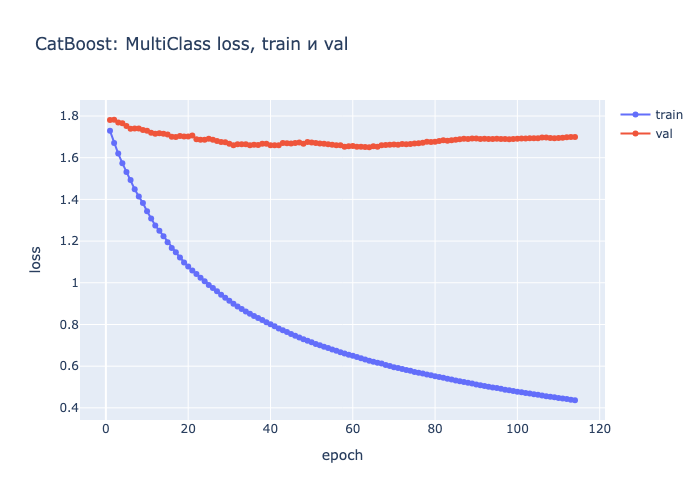

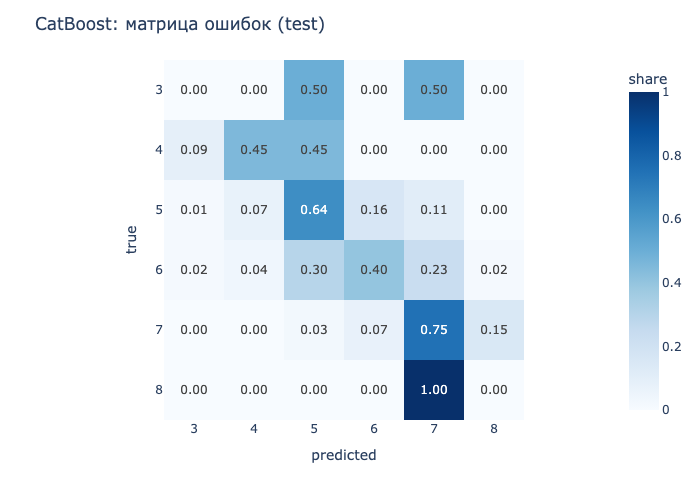

In [6]:
fig = plot_curves(run.history, "loss", title="CatBoost: MultiClass loss, train и val")
fig.show()
fig = plot_confusion(
    run.predictions, labels=[str(c) for c in CLASSES], title="CatBoost: матрица ошибок (test)"
)
fig.show()

> **Вывод:**

`CatBoost` дал `F1 macro` 0.2925 на val и 0.3293 на test против 0.0995 у `Dummy`, так что модель действительно что-то выучила, а не просто угадывает частый класс. Однако до `CatBoost Optuna` из ml-2 ЛР1 (0.3532 на test) она не дотягивает. Я посчитал это ожидаемым: здесь train меньше на 256 объектов, которые ушли в val, а в ml-2 ЛР1 early stopping шел прямо по test, то есть test участвовал в выборе итерации. Честно говоря, до меня это дошло только сейчас, когда пришлось заводить отдельную валидацию.

Кривые показывают переобучение довольно рано: минимум val loss на 64-й итерации (1.6505), дальше он растет, хотя train loss продолжает падать до 0.4365. Весь `F1 macro` держится на классах `4`–`7`, а `3` и `8` модель не угадала ни разу — при 2 и 3 объектах в test это и неудивительно. `auto_class_weights='Balanced'` заметно тянет модель к редким классам: у `quality=7` recall 0.750 при precision 0.380, то есть класс находится, но ценой ложных срабатываний из соседнего `6`. Если говорить по простому — val в 256 объектов слишком мал для устойчивой оценки, поэтому сравнивать с нейросетями дальше стоит на нескольких seeds.

## 1.3 FT-Transformer и GANDALF «из коробки»

TODO (этап 2: идеи моделей, параметры, эпохи, val-метрика, время, кривые)

> **Вывод:** TODO

## 1.4 Исследование и оптимизация моделей

TODO (этап 3: гипотеза → значения → val F1 macro → вывод)

> **Вывод:** TODO

## 1.5 Сравнение моделей и их поведение

TODO (этап 4)

### Test

> **Вывод:** TODO

### Анализ ошибок

> **Вывод:** TODO

### Интерпретация

> **Вывод:** TODO

## Проверка на объектах, созданных вручную

TODO (этап 5: ≥ 10 объектов, предсказания трёх моделей)

> **Вывод:** TODO

# II. Самостоятельное исследование архитектуры

## 2.1 Данные и экспериментальный протокол

TODO (этап 6)

> **Вывод:** TODO

## 2.2 Подготовка данных и baseline

TODO (этап 6: признаки, preprocessing, выборки, изменения для новых моделей)

> **Вывод:** TODO

## 2.3 Новые архитектуры: TabLDM и TabM

TODO (этап 6: выбор реализации, идея каждой модели)

> **Вывод:** TODO

## 2.4 Исследование TabLDM и TabM

TODO (этап 7: базовые конфигурации, эксперименты, доля train → F1, seeds, время)

> **Вывод:** TODO

## 2.5 Итоговое сравнение

TODO (этап 8)

### Test

> **Вывод:** TODO

### Анализ ошибок

> **Вывод:** TODO

### Интерпретация

> **Вывод:** TODO

## Повтор проверки на ручных объектах

TODO (этап 8: все модели на тех же объектах)

> **Вывод:** TODO

# Итоговые выводы

TODO (этап 9)